## <span style="color:#1F4E79;">**BTL-Generated Choice Data Fitted with a CDM Model**</span>


This notebook studies model misspecification by generating synthetic choice observations from a BTL and fitting the BTL model to the same data.



In [1]:
# Import numerical, plotting, Bradley--Terry, and CDM utilities.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from bradley_terry import (
    average_negative_log_likelihood,
    center_parameters,
    generate_uniform_comparison_data,
)

from context_dependent_model import (
    CDMChoiceData,
    average_cdm_negative_log_likelihood,
    optimize_full_cdm_with_adam,
    split_cdm_choice_data,
)

In [2]:
# Configure plotting defaults and create the BTL-to-CDM output directories.

PROJECT_ROOT = next(
    path
    for path in [
        Path.cwd(),
        *Path.cwd().parents,
    ]
    if (
        path / "pyproject.toml"
    ).exists()
)

BTL_CDM_FIGURE_DIRECTORY = (
    PROJECT_ROOT
    / "docs"
    / "thesis"
    / "images"
    / "experiments"
    / "context_dependent_model"
    / "btl_cdm"
)

BTL_CDM_TABLE_DIRECTORY = (
    PROJECT_ROOT
    / "docs"
    / "thesis"
    / "tables"
    / "experiments"
    / "context_dependent_model"
    / "btl_cdm"
)

BTL_CDM_RESULT_DIRECTORY = (
    PROJECT_ROOT
    / "results"
    / "tables"
    / "context_dependent_model"
    / "btl_cdm"
)

for output_directory in [
    BTL_CDM_FIGURE_DIRECTORY,
    BTL_CDM_TABLE_DIRECTORY,
    BTL_CDM_RESULT_DIRECTORY,
]:
    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "figure.figsize": (8, 5),
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "legend.fontsize": 9,
        "grid.alpha": 0.25,
    }
)

pd.DataFrame(
    {
        "Output": [
            "Figures",
            "LaTeX tables",
            "Numerical results",
        ],
        "Directory": [
            BTL_CDM_FIGURE_DIRECTORY,
            BTL_CDM_TABLE_DIRECTORY,
            BTL_CDM_RESULT_DIRECTORY,
        ],
    }
)

,Output,Directory
0,Figures,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
1,LaTeX tables,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
2,Numerical results,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...


In [3]:
# Define reproducible settings for the baseline BTL-to-CDM experiment.

SEED = 20260831

NUMBER_OF_ITEMS = 5
NUMBER_OF_COMPARISONS = 1_000

BTL_PARAMETER_SCALE = 0.5
TRAIN_FRACTION = 0.8

DEVICE = torch.device("cpu")
DTYPE = torch.float64

random_generator = np.random.default_rng(
    SEED
)

torch.manual_seed(SEED)

baseline_settings = pd.DataFrame(
    {
        "Setting": [
            "Random seed",
            "Number of items",
            "Number of comparisons",
            "BTL parameter scale",
            "Training fraction",
            "Test fraction",
            "PyTorch device",
            "PyTorch dtype",
        ],
        "Value": [
            SEED,
            NUMBER_OF_ITEMS,
            NUMBER_OF_COMPARISONS,
            BTL_PARAMETER_SCALE,
            TRAIN_FRACTION,
            1.0 - TRAIN_FRACTION,
            str(DEVICE),
            str(DTYPE),
        ],
    }
)

baseline_settings


,Setting,Value
0,Random seed,20260831
1,Number of items,5
2,Number of comparisons,1000
3,BTL parameter scale,0.5
4,Training fraction,0.8
5,Test fraction,0.2
6,PyTorch device,cpu
7,PyTorch dtype,torch.float64


 Generate the True BTL Parameters


In [4]:
# Generate and centre the true BTL item parameters.

raw_btl_parameters = random_generator.normal(
    loc=0.0,
    scale=BTL_PARAMETER_SCALE,
    size=NUMBER_OF_ITEMS,
)

true_btl_parameters = center_parameters(
    raw_btl_parameters
)

true_btl_parameter_table = pd.DataFrame(
    {
        "Item": np.arange(NUMBER_OF_ITEMS),
        "Raw parameter": raw_btl_parameters,
        "Centred parameter": true_btl_parameters,
    }
)

print(
    "Sum of centred parameters:",
    f"{true_btl_parameters.sum():.8f}",
)

true_btl_parameter_table.style.format(
    {
        "Raw parameter": "{:.4f}",
        "Centred parameter": "{:.4f}",
    }
)

Sum of centred parameters: 0.00000000


,Item,Raw parameter,Centred parameter
0,0,-0.1598,-0.1983
1,1,-0.1305,-0.1690
2,2,0.1107,0.0722
3,3,0.7842,0.7457
4,4,-0.4123,-0.4507


In [5]:
# Calculate the BTL choice probabilities for items zero and one.

FIRST_ITEM = 0
SECOND_ITEM = 1

parameter_difference = (
    true_btl_parameters[FIRST_ITEM]
    - true_btl_parameters[SECOND_ITEM]
)

probability_first_beats_second = (
    1.0
    / (
        1.0
        + np.exp(-parameter_difference)
    )
)

probability_second_beats_first = (
    1.0
    - probability_first_beats_second
)

pairwise_probability_summary = pd.DataFrame(
    {
        "Quantity": [
            "Parameter of item 0",
            "Parameter of item 1",
            "Parameter difference",
            "P(item 0 beats item 1)",
            "P(item 1 beats item 0)",
            "Probability sum",
        ],
        "Value": [
            true_btl_parameters[FIRST_ITEM],
            true_btl_parameters[SECOND_ITEM],
            parameter_difference,
            probability_first_beats_second,
            probability_second_beats_first,
            (
                probability_first_beats_second
                + probability_second_beats_first
            ),
        ],
    }
)

pairwise_probability_summary.style.format(
    {
        "Value": "{:.4f}",
    }
)

,Quantity,Value
0,Parameter of item 0,-0.1983
1,Parameter of item 1,-0.1690
2,Parameter difference,-0.0293
3,P(item 0 beats item 1),0.4927
4,P(item 1 beats item 0),0.5073
5,Probability sum,1.0000


In [6]:
# Generate pairwise comparisons from the true BTL parameters.

comparisons = generate_uniform_comparison_data(
    true_parameters=true_btl_parameters,
    number_of_comparisons=NUMBER_OF_COMPARISONS,
    rng=random_generator,
)

comparison_preview = pd.DataFrame(
    comparisons[:10],
    columns=[
        "Winner",
        "Loser",
    ],
)

print(
    "Number of generated comparisons:",
    f"{len(comparisons):,}",
)

comparison_preview

Number of generated comparisons: 1,000


,Winner,Loser
0,3,2
1,4,1
2,0,4
3,0,4
4,3,2
5,2,1
6,3,4
7,3,1
8,4,0
9,0,4


In [7]:
# Summarise item appearances, wins, and losses in the generated comparisons.

comparison_array = np.asarray(
    comparisons,
    dtype=int,
)

winners = comparison_array[:, 0]
losers = comparison_array[:, 1]

item_win_counts = np.bincount(
    winners,
    minlength=NUMBER_OF_ITEMS,
)

item_loss_counts = np.bincount(
    losers,
    minlength=NUMBER_OF_ITEMS,
)

item_appearance_counts = (
    item_win_counts
    + item_loss_counts
)

item_win_rates = (
    item_win_counts
    / item_appearance_counts
)

comparison_coverage_summary = pd.DataFrame(
    {
        "Item": np.arange(NUMBER_OF_ITEMS),
        "True BTL parameter": true_btl_parameters,
        "Appearances": item_appearance_counts,
        "Wins": item_win_counts,
        "Losses": item_loss_counts,
        "Observed win rate": item_win_rates,
    }
)

print(
    "Contains self-comparisons:",
    bool(np.any(winners == losers)),
)

comparison_coverage_summary.style.format(
    {
        "True BTL parameter": "{:.4f}",
        "Observed win rate": "{:.3f}",
    }
)

Contains self-comparisons: False


,Item,True BTL parameter,Appearances,Wins,Losses,Observed win rate
0,0,-0.1983,364,153,211,0.420
1,1,-0.1690,423,183,240,0.433
2,2,0.0722,414,207,207,0.500
3,3,0.7457,408,302,106,0.740
4,4,-0.4507,391,155,236,0.396


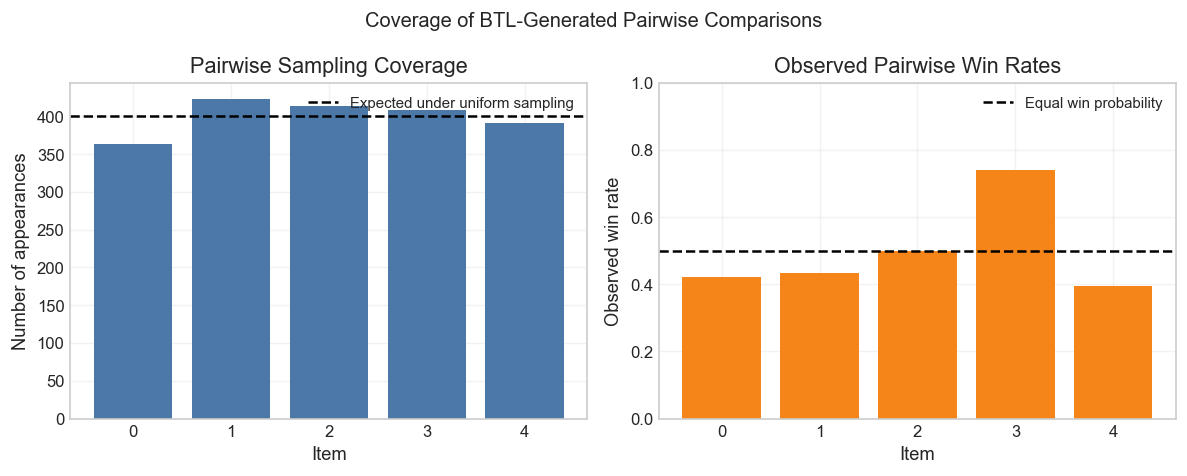

In [8]:
# Plot item appearances and observed win rates in the generated data.

items = np.arange(
    NUMBER_OF_ITEMS
)

expected_appearances = (
    2
    * NUMBER_OF_COMPARISONS
    / NUMBER_OF_ITEMS
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
)

axes[0].bar(
    items,
    item_appearance_counts,
    color="#4C78A8",
)

axes[0].axhline(
    expected_appearances,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Expected under uniform sampling",
)

axes[0].set_xlabel("Item")
axes[0].set_ylabel("Number of appearances")
axes[0].set_title("Pairwise Sampling Coverage")
axes[0].set_xticks(items)
axes[0].legend()

axes[1].bar(
    items,
    item_win_rates,
    color="#F58518",
)

axes[1].axhline(
    0.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Equal win probability",
)

axes[1].set_xlabel("Item")
axes[1].set_ylabel("Observed win rate")
axes[1].set_title("Observed Pairwise Win Rates")
axes[1].set_xticks(items)
axes[1].set_ylim(0.0, 1.0)
axes[1].legend()

figure.suptitle(
    "Coverage of BTL-Generated Pairwise Comparisons"
)

figure.tight_layout()

figure.savefig(
    BTL_CDM_FIGURE_DIRECTORY
    / "01_btl_comparison_coverage.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.show()

Convert the Pairwise Data to the CDM Representation

In [9]:
# Convert the BTL comparisons into the tensor representation required by the CDM.

ordering_random_generator = np.random.default_rng(
    SEED + 1
)

cdm_choice_sets_array = comparison_array.copy()

cdm_chosen_positions_array = np.zeros(
    NUMBER_OF_COMPARISONS,
    dtype=int,
)

swap_pair_order = (
    ordering_random_generator.random(
        NUMBER_OF_COMPARISONS
    )
    < 0.5
)

cdm_choice_sets_array[swap_pair_order] = (
    cdm_choice_sets_array[swap_pair_order][
        :,
        ::-1,
    ]
)

cdm_chosen_positions_array[
    swap_pair_order
] = 1

cdm_choice_sets = torch.as_tensor(
    cdm_choice_sets_array,
    dtype=torch.long,
    device=DEVICE,
)

cdm_chosen_positions = torch.as_tensor(
    cdm_chosen_positions_array,
    dtype=torch.long,
    device=DEVICE,
)

cdm_choice_mask = torch.ones_like(
    cdm_choice_sets,
    dtype=torch.bool,
)

btl_generated_cdm_data = CDMChoiceData(
    choice_sets=cdm_choice_sets,
    chosen_positions=cdm_chosen_positions,
    choice_mask=cdm_choice_mask,
)

recovered_chosen_items = (
    btl_generated_cdm_data.choice_sets[
        torch.arange(
            NUMBER_OF_COMPARISONS,
            device=DEVICE,
        ),
        btl_generated_cdm_data.chosen_positions,
    ]
)

conversion_preview = pd.DataFrame(
    {
        "Original winner": winners[:10],
        "Stored item at position 0": (
            cdm_choice_sets_array[:10, 0]
        ),
        "Stored item at position 1": (
            cdm_choice_sets_array[:10, 1]
        ),
        "Chosen position": (
            cdm_chosen_positions_array[:10]
        ),
        "Recovered chosen item": (
            recovered_chosen_items[:10]
            .cpu()
            .numpy()
        ),
    }
)

print(
    "All original winners preserved:",
    bool(
        np.array_equal(
            winners,
            recovered_chosen_items.cpu().numpy(),
        )
    ),
)

conversion_preview

All original winners preserved: True


,Original winner,Stored item at position 0,Stored item at position 1,Chosen position,Recovered chosen item
0,3,3,2,0,3
1,4,4,1,0,4
2,0,4,0,1,0
3,0,4,0,1,0
4,3,3,2,0,3
5,2,2,1,0,2
6,3,4,3,1,3
7,3,3,1,0,3
8,4,4,0,0,4
9,0,4,0,1,0


In [10]:
# Split the BTL-generated CDM data into reproducible training and test sets.

training_cdm_data, test_cdm_data = (
    split_cdm_choice_data(
        data=btl_generated_cdm_data,
        train_fraction=TRAIN_FRACTION,
        random_seed=SEED + 2,
    )
)

training_choice_set_sizes = (
    training_cdm_data.choice_mask
    .sum(dim=1)
    .cpu()
    .numpy()
)

test_choice_set_sizes = (
    test_cdm_data.choice_mask
    .sum(dim=1)
    .cpu()
    .numpy()
)

split_summary = pd.DataFrame(
    {
        "Dataset": [
            "Training",
            "Test",
        ],
        "Number of observations": [
            len(training_cdm_data.choice_sets),
            len(test_cdm_data.choice_sets),
        ],
        "Fraction": [
            len(training_cdm_data.choice_sets)
            / NUMBER_OF_COMPARISONS,
            len(test_cdm_data.choice_sets)
            / NUMBER_OF_COMPARISONS,
        ],
        "Minimum choice-set size": [
            training_choice_set_sizes.min(),
            test_choice_set_sizes.min(),
        ],
        "Maximum choice-set size": [
            training_choice_set_sizes.max(),
            test_choice_set_sizes.max(),
        ],
    }
)

split_summary.style.format(
    {
        "Fraction": "{:.2f}",
    }
)

,Dataset,Number of observations,Fraction,Minimum choice-set size,Maximum choice-set size
0,Training,800,0.80,2,2
1,Test,200,0.20,2,2


In [11]:
# Recover explicit winner--loser pairs from pairwise CDM data.

def convert_pairwise_cdm_data_to_comparisons(
    data,
):
    """Convert pairwise CDMChoiceData into winner--loser pairs."""

    choice_sets = (
        data.choice_sets
        .detach()
        .cpu()
        .numpy()
    )

    chosen_positions = (
        data.chosen_positions
        .detach()
        .cpu()
        .numpy()
    )

    observation_indices = np.arange(
        len(choice_sets)
    )

    winners = choice_sets[
        observation_indices,
        chosen_positions,
    ]

    loser_positions = (
        1
        - chosen_positions
    )

    losers = choice_sets[
        observation_indices,
        loser_positions,
    ]

    return np.column_stack(
        [
            winners,
            losers,
        ]
    ).astype(int)


training_comparisons = (
    convert_pairwise_cdm_data_to_comparisons(
        training_cdm_data
    )
)

test_comparisons = (
    convert_pairwise_cdm_data_to_comparisons(
        test_cdm_data
    )
)

split_comparison_preview = pd.concat(
    [
        pd.DataFrame(
            training_comparisons[:5],
            columns=["Winner", "Loser"],
        ).assign(Dataset="Training"),
        pd.DataFrame(
            test_comparisons[:5],
            columns=["Winner", "Loser"],
        ).assign(Dataset="Test"),
    ],
    ignore_index=True,
)

print(
    "Training comparisons:",
    len(training_comparisons),
)

print(
    "Test comparisons:",
    len(test_comparisons),
)

split_comparison_preview[
    [
        "Dataset",
        "Winner",
        "Loser",
    ]
]

Training comparisons: 800
Test comparisons: 200


,Dataset,Winner,Loser
0,Training,2,4
1,Training,2,4
2,Training,0,3
3,Training,1,0
4,Training,4,2
5,Test,3,4
6,Test,0,2
7,Test,3,1
8,Test,3,1
9,Test,2,1


In [12]:
# Evaluate the uniform baseline and true BTL model on both data splits.

uniform_btl_parameters = np.zeros(
    NUMBER_OF_ITEMS
)

uniform_training_nll = (
    average_negative_log_likelihood(
        parameters=uniform_btl_parameters,
        comparisons=training_comparisons,
    )
)

uniform_test_nll = (
    average_negative_log_likelihood(
        parameters=uniform_btl_parameters,
        comparisons=test_comparisons,
    )
)

true_btl_training_nll = (
    average_negative_log_likelihood(
        parameters=true_btl_parameters,
        comparisons=training_comparisons,
    )
)

true_btl_test_nll = (
    average_negative_log_likelihood(
        parameters=true_btl_parameters,
        comparisons=test_comparisons,
    )
)

btl_baseline_summary = pd.DataFrame(
    {
        "Model": [
            "Uniform baseline",
            "True BTL",
        ],
        "Training NLL": [
            uniform_training_nll,
            true_btl_training_nll,
        ],
        "Test NLL": [
            uniform_test_nll,
            true_btl_test_nll,
        ],
    }
)

btl_baseline_summary.style.format(
    {
        "Training NLL": "{:.4f}",
        "Test NLL": "{:.4f}",
    }
)

,Model,Training NLL,Test NLL
0,Uniform baseline,0.6931,0.6931
1,True BTL,0.6472,0.6218


In [13]:
# Compare the parameter counts of the BTL and full-CDM models.

number_of_btl_free_parameters = (
    NUMBER_OF_ITEMS
    - 1
)

number_of_full_cdm_free_parameters = (
    NUMBER_OF_ITEMS
    * (NUMBER_OF_ITEMS - 1)
    - 1
)

number_of_training_observations = len(
    training_cdm_data.choice_sets
)

model_complexity_summary = pd.DataFrame(
    {
        "Model": [
            "Centred BTL",
            "Full CDM",
        ],
        "Number of free parameters": [
            number_of_btl_free_parameters,
            number_of_full_cdm_free_parameters,
        ],
        "Training observations per parameter": [
            (
                number_of_training_observations
                / number_of_btl_free_parameters
            ),
            (
                number_of_training_observations
                / number_of_full_cdm_free_parameters
            ),
        ],
        "Parameter recovery from pairwise-only data": [
            "Identifiable under suitable comparison coverage",
            "Not uniquely identifiable",
        ],
    }
)

model_complexity_summary.style.format(
    {
        "Training observations per parameter": "{:.2f}",
    }
)

,Model,Number of free parameters,Training observations per parameter,Parameter recovery from pairwise-only data
0,Centred BTL,4,200.00,Identifiable under suitable comparison coverage
1,Full CDM,19,42.11,Not uniquely identifiable


Fit the Full CDM to the BTL-Generated Data

In [14]:
# Fit the full CDM to the BTL-generated pairwise training data.

torch.manual_seed(
    SEED + 3
)

cdm_optimization_result = (
    optimize_full_cdm_with_adam(
        number_of_items=NUMBER_OF_ITEMS,
        training_data=training_cdm_data,
        learning_rate=0.05,
        gradient_tolerance=1e-5,
        nll_tolerance=1e-9,
        patience=50,
        maximum_epochs=5_000,
        dtype=DTYPE,
    )
)

cdm_optimization_summary = pd.DataFrame(
    {
        "Quantity": [
            "Epochs completed",
            "Runtime (seconds)",
            "Converged",
            "Stopping reason",
        ],
        "Value": [
            cdm_optimization_result.epochs_completed,
            (
                cdm_optimization_result
                .runtime_seconds
            ),
            cdm_optimization_result.converged,
            (
                cdm_optimization_result
                .stopping_reason
            ),
        ],
    }
)

cdm_optimization_summary

,Quantity,Value
0,Epochs completed,159
1,Runtime (seconds),0.185078
2,Converged,True
3,Stopping reason,gradient tolerance reached


In [15]:
# Compare the predictive NLL of the uniform, true-BTL, and fitted-CDM models.

with torch.no_grad():
    fitted_cdm_training_nll = float(
        average_cdm_negative_log_likelihood(
            interaction_matrix=(
                cdm_optimization_result
                .interaction_matrix
            ),
            choice_sets=(
                training_cdm_data.choice_sets
            ),
            chosen_positions=(
                training_cdm_data.chosen_positions
            ),
            choice_mask=(
                training_cdm_data.choice_mask
            ),
        ).item()
    )

    fitted_cdm_test_nll = float(
        average_cdm_negative_log_likelihood(
            interaction_matrix=(
                cdm_optimization_result
                .interaction_matrix
            ),
            choice_sets=(
                test_cdm_data.choice_sets
            ),
            chosen_positions=(
                test_cdm_data.chosen_positions
            ),
            choice_mask=(
                test_cdm_data.choice_mask
            ),
        ).item()
    )

predictive_performance_summary = pd.DataFrame(
    {
        "Model": [
            "Uniform baseline",
            "True BTL",
            "Fitted full CDM",
        ],
        "Training NLL": [
            uniform_training_nll,
            true_btl_training_nll,
            fitted_cdm_training_nll,
        ],
        "Test NLL": [
            uniform_test_nll,
            true_btl_test_nll,
            fitted_cdm_test_nll,
        ],
    }
)

predictive_performance_summary[
    "Test minus training NLL"
] = (
    predictive_performance_summary["Test NLL"]
    - predictive_performance_summary[
        "Training NLL"
    ]
)

predictive_performance_summary.style.format(
    {
        "Training NLL": "{:.4f}",
        "Test NLL": "{:.4f}",
        "Test minus training NLL": "{:.4f}",
    }
)

,Model,Training NLL,Test NLL,Test minus training NLL
0,Uniform baseline,0.6931,0.6931,0.0000
1,True BTL,0.6472,0.6218,-0.0254
2,Fitted full CDM,0.6393,0.6185,-0.0208


In [16]:
# Quantify the predictive gap between the fitted CDM and true BTL model.

training_excess_nll = (
    fitted_cdm_training_nll
    - true_btl_training_nll
)

test_excess_nll = (
    fitted_cdm_test_nll
    - true_btl_test_nll
)

cdm_test_improvement_over_uniform = (
    uniform_test_nll
    - fitted_cdm_test_nll
)

predictive_gap_summary = pd.DataFrame(
    {
        "Metric": [
            "CDM training excess NLL",
            "CDM test excess NLL",
            "CDM test improvement over uniform",
        ],
        "Value": [
            training_excess_nll,
            test_excess_nll,
            cdm_test_improvement_over_uniform,
        ],
    }
)

predictive_gap_summary.style.format(
    {
        "Value": "{:.6f}",
    }
)

,Metric,Value
0,CDM training excess NLL,-0.007886
1,CDM test excess NLL,-0.003338
2,CDM test improvement over uniform,0.074675
